# E3 — TCR-XGBoost

Evaluación local del método elegido por el usuario. Los resultados se guardan separados de los modelos previos y del dashboard.

## TCR: qué se implementa

Se sigue [TCR (Zühlke y Kudenko,2025)](https://doi.org/10.1007/s10994-024-06704-x),
con [referencia oficial](https://github.com/montymaxzuehlke/tcr), commit
`b73caef801b002569dbb95fbb7b229f08e0a78c2`. La sensibilidad de cada fila es el máximo
de `|y_i−y_j| / (distancia(x_i,x_j)+1e-7)` en el fit; el objetivo se lleva a[0,1].
Robustez=`1/(1+sensibilidad)`. Se reduce el peso de la fracción menos robusta y se
reentrena XGBoost. Los pesos son positivos: ninguna fila se elimina.

Para distancias se usa preparación SVM y MinMax aprendido en fit. El XGBoost conserva
su propia mediana/moda y categorías nativas. Se reutilizan los hiperparámetros base
seleccionados en la búsqueda clásica **dentro del fit externo correspondiente**; para
el ajuste final se usan los elegidos con todo train. No se usan los parámetros finales
del train completo dentro de los folds externos. Es una selección secuencial de base
y ponderación en train, no una búsqueda conjunta de todos los hiperparámetros.

Grilla: control sin ponderación + fracción .05/.10/.20 × peso .3/.6/.9, diez candidatos.
Todos los cálculos de robustez se repiten con solo el fit interno. Las métricas de
validación/test se calculan sin pesos. Los outliers se conservan; robustez baja no
implica que una fila sea errónea. El archivo pesos_train.csv contiene robustez y pesos
en orden canónico, sin IDs ni notas.

## Datos y protocolo compartido

Misma fuente real y reglas de negocio de entregable3.py; sin aumentación, mismos15
predictores y objetivo nota_primer_parcial. ID, periodo, fila fuente y nota_final
excluidos como entradas. Train1309 filas/1293 estudiantes, test202530 con188 filas/
188 estudiantes, sin personas compartidas. Los cinco folds externos se verifican
contra los archivos canónicos. Todo preprocesador se aprende exclusivamente en fit.

La configuración final se guarda antes de predecir test. RMSE, MAE, MAPE(%) y R²
se calculan con la función del tablero en escala original, sin recortar predicciones.
Se separan media/SD de folds(ddof0), OOF reunido y test temporal. MAPE es sensible
a notas próximas a cero. Las métricas de CV no se mezclan con las de test.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
BOOK=Path.cwd() if (Path.cwd()/'entregable3.py').exists() else Path.cwd()/'Precalculo'
sys.path.insert(0,str(BOOK.resolve()))
from comparacion_seleccionados_e3 import run,candidate_grid
key='tcr_xgboost'
display(pd.DataFrame(candidate_grid(key)))
report=run(key,force=False)
display(pd.DataFrame(report['cv']).round(6))
display(pd.DataFrame(report['fold_audit']))
print('Parámetros finales:',report['best_params'])
print('Base XGBoost:',report['xgboost_base_params'])

,fraction,weight
0,0.00,1.0
1,0.05,0.3
2,0.05,0.6
3,0.05,0.9
4,0.10,0.3
5,0.10,0.6
6,0.10,0.9
7,0.20,0.3
8,0.20,0.6
9,0.20,0.9


tcr_xgboost: resultado completo verificado.


,metrica,media_cv,sd_cv,OOF_agrupado
0,RMSE,0.814476,0.031027,0.815060
1,MAE,0.645405,0.023918,0.645400
2,MAPE (%),24.181795,1.897429,24.181284
3,R²,0.466177,0.042133,0.468132


,fold,fit_rows,validation_rows,shared_students,best_params,xgboost_base_params,inner_rmse,seconds
0,1,1047,262,0,"{'fraction': 0.1, 'weight': 0.9}","{'modelo__learning_rate': 0.01, 'modelo__max_d...",0.831676,57.455037
1,2,1047,262,0,"{'fraction': 0.2, 'weight': 0.6}","{'modelo__learning_rate': 0.03, 'modelo__max_d...",0.800069,52.034077
2,3,1047,262,0,"{'fraction': 0.2, 'weight': 0.3}","{'modelo__learning_rate': 0.03, 'modelo__max_d...",0.789449,53.950071
3,4,1047,262,0,"{'fraction': 0.0, 'weight': 1.0}","{'modelo__learning_rate': 0.03, 'modelo__max_d...",0.806573,51.406762
4,5,1048,261,0,"{'fraction': 0.05, 'weight': 0.3}","{'modelo__learning_rate': 0.03, 'modelo__max_d...",0.800604,49.884177


Parámetros finales: {'fraction': 0.2, 'weight': 0.3}
Base XGBoost: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 2, 'modelo__n_estimators': 300}


## Comparación con las referencias anteriores

Cada panel tiene su propia métrica y escala. Naranja identifica este método;
verde, TabPFN original. La tabla incluye las etapas nuevas completadas hasta este
método, respetando el orden TCR → TabICL → HRT. Los modelos activos del dashboard
y los notebooks históricos se conservan.

,Modelo,RMSE,MAE,MAPE (%),R²
8,TabPFN 2.5 original,0.898277,0.715491,27.761050,0.464223
9,TabPFN 2.5 fine-tuned,0.901370,0.722380,28.072635,0.460527
6,XGBoost,0.906274,0.728918,28.404775,0.454641
11,TCR-XGBoost,0.907695,0.737890,28.571924,0.452929
3,Ridge,0.917090,0.754511,29.572140,0.441545
4,Lasso,0.919650,0.753040,29.551967,0.438424
2,KNN,0.923270,0.754027,29.584495,0.433995
7,logicDT propio (adaptado),0.926438,0.760954,29.658839,0.430104
0,SVM lineal,0.927706,0.755443,29.664556,0.428543
5,Random Forest,0.939635,0.765847,29.732021,0.413751


,referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_dos_pares
0,SVM lineal,RMSE,-0.020010,-0.053416,0.013774,0.24432,0.48864
1,SVM lineal,R²,0.024387,-0.017132,0.065128,0.24432,0.48864
2,TabPFN original,RMSE,0.009418,-0.012722,0.031751,0.40842,0.48864
3,TabPFN original,R²,-0.011293,-0.037940,0.015603,0.40842,0.48864


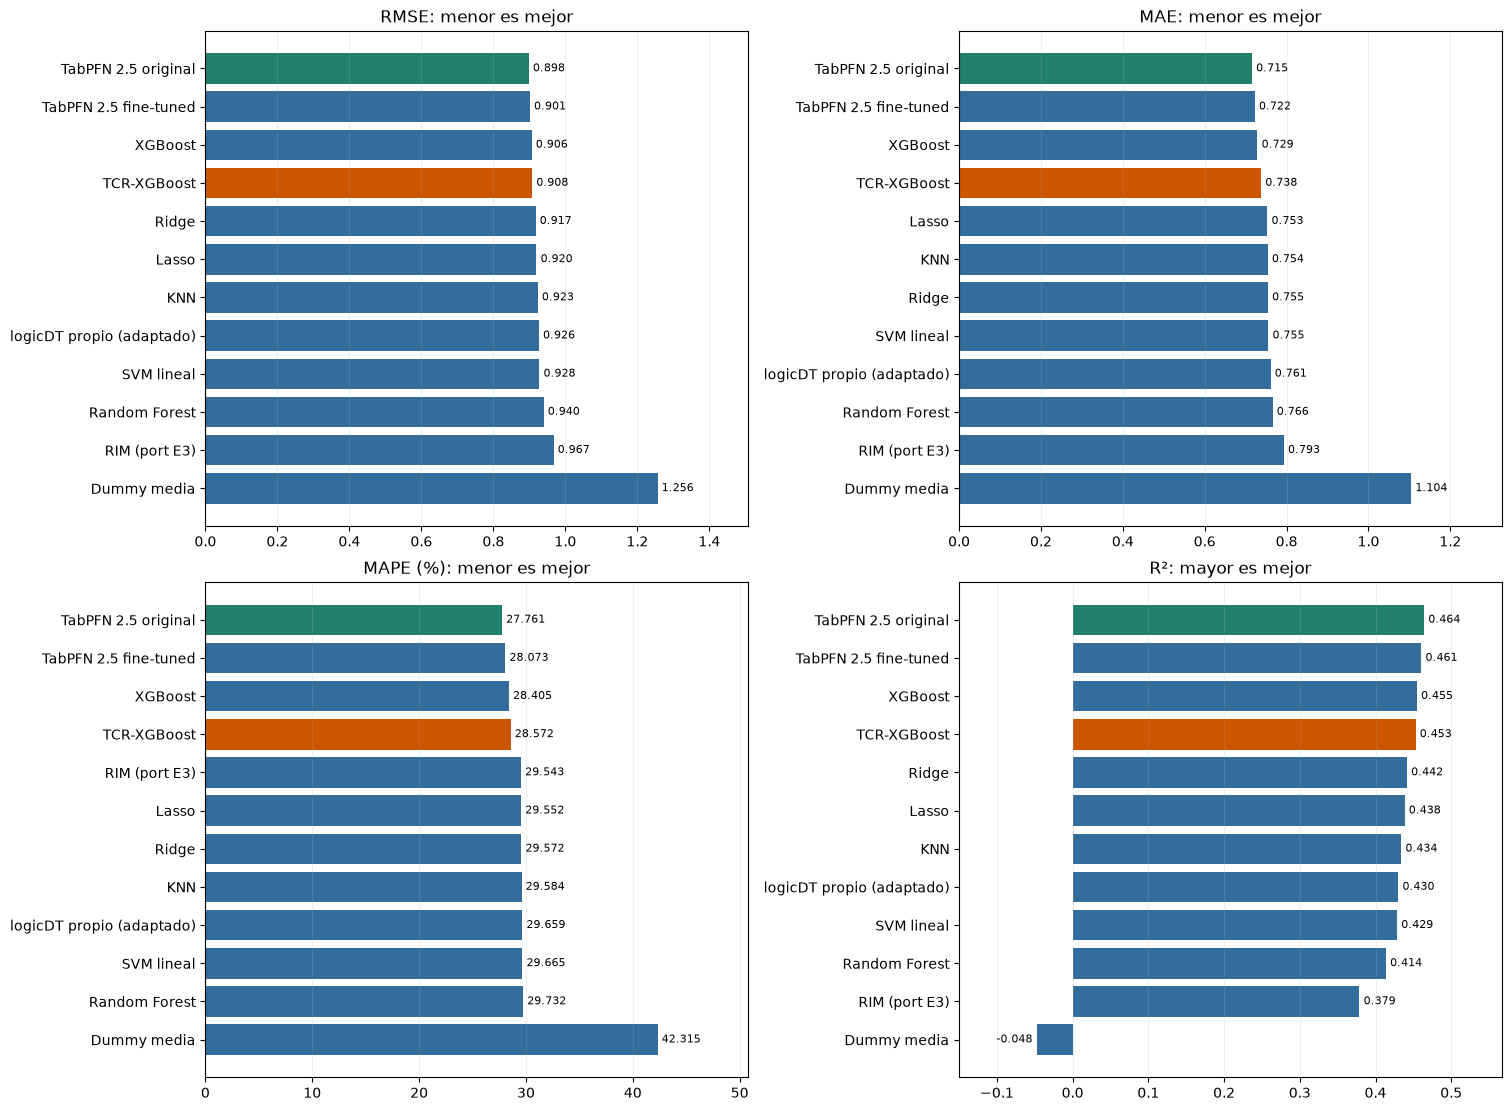

,modelo,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_familia_conocida
0,KNN,RMSE,-0.004436,-0.044821,0.036077,0.82690,1.00000
1,Ridge,RMSE,-0.010615,-0.032070,0.005268,0.31128,1.00000
2,Lasso,RMSE,-0.008056,-0.020001,0.001928,0.15770,1.00000
3,Random Forest,RMSE,0.011930,-0.024657,0.048603,0.51846,1.00000
4,XGBoost,RMSE,-0.021432,-0.054703,0.012122,0.21102,1.00000
5,logicDT,RMSE,-0.001268,-0.036852,0.030833,0.94434,1.00000
6,TabPFN ajustado,RMSE,-0.026336,-0.056160,0.002756,0.08018,0.72162
7,RIM,RMSE,0.039507,-0.013963,0.095171,0.16266,1.00000
8,TabPFN original,RMSE,-0.029428,-0.061618,0.002094,0.06888,0.68880
9,TCR-XGBoost,RMSE,-0.020010,-0.053416,0.013774,0.24432,1.00000


In [2]:
from evaluar_tabpfn25_finetuned_e3 import show
show(report)
display(pd.DataFrame(report['family_vs_svm']).round(6))

## Contrastes estadísticos

Permutación bilateral pareada por estudiante99999 y bootstrap pareado10000,
semilla42. Diferencia=método actual menos referencia: negativa favorece al actual
para RMSE y positiva para R². El p-valor de ambas métricas coincide porque son el
mismo contraste sobre SSE en el mismo test, no dos evidencias independientes.

Se aplica Holm a los dos pares actuales (SVM y TabPFN original) y se muestra además
Holm para la familia acumulada de candidatos conocidos frente al SVM. Los IC son
marginales, sin ajuste simultáneo. No basta que p sea pequeño: debe comprobarse
la dirección de la diferencia. La inferencia sigue siendo exploratoria por uso
repetido de202530 y es condicional a estos modelos; no incluye variabilidad de
reentrenamiento ni demuestra equivalencia si no se rechaza H0.

In [3]:
for comp in report['paired_comparisons']:
    row=comp['rows'][0]
    print(comp['referencia'],'deltaRMSE=',round(row['diferencia_ajustado_menos_referencia'],6),
          'p=',row['p_bilateral'],'p Holm=',row['p_Holm_dos_pares'])
print('Familia conocida:',len(report['family_vs_svm']),'candidatos vs SVM')
print('Resultados:',report['outputs'])
print('Modelo guardado localmente:',report['private_model'])

SVM lineal deltaRMSE= -0.02001 p= 0.24432 p Holm= 0.48864
TabPFN original deltaRMSE= 0.009418 p= 0.40842 p Holm= 0.48864
Familia conocida: 10 candidatos vs SVM
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\tcr_xgboost
Modelo guardado localmente: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\modelos_preentrenados\tcr_xgboost\modelo_final.joblib


## Reproducibilidad

Hashes de fuente, protocolo, módulos, versiones y referencias en reporte.json y
protocolo.json. Predicciones OOF/test sin IDs, grillas internas cuando corresponda,
auditoría y comparaciones CSV. Los estimadores/contextos se guardan únicamente en
modelos_preentrenados/, ignorado en Git. Usar el venv compartido y las versiones
de requirements_seleccionados_e3.txt; no se crea otro entorno.